# 02_als_bf_lsh: ALS + Brute-force kNN + LSH on the 1M subset

CO5135 Big Data mini-project (Phase 2 + 3).

**Input:** output of notebook `00_prepare_data` (Add Input > Your Work > `00_prepare_data`).

**Steps**

1. ALS: tune `rank` and `regParam` on a validation split, report test RMSE.
2. Item vectors: ALS item factors, keep movies with at least 20 ratings in train, normalize to unit length
   (so cosine similarity = 1 - d²/2 with Euclidean distance d).
3. Exact top-K neighbors: NumPy (single machine) and Spark brute-force (cross join, all pairs).
4. LSH, two variants, both measured by Recall@10 against the exact neighbors, candidate pairs and runtime:
   - **BRP**: Spark built-in `BucketedRandomProjectionLSH` (OR over hash tables only).
   - **SimHash banding**: random-hyperplane LSH with banding (AND inside a band, OR across bands),
     implemented with Spark DataFrame joins. This is the S-curve technique from the LSH lecture.
5. Item-based recommendation from each neighbor table, Precision@10 on the test set,
   compared with a popularity baseline.

**Output (in `results/`):** `als_tuning_1m.csv`, `bf_vs_lsh_1m.csv`, `lsh_tradeoff_1m.png`,
`bf_vs_lsh_time_1m.png`, `summary_1m.json`.

In [1]:
# ===== SETUP =====
import os, glob, time, json, shutil
!pip install -q pyspark

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import BucketedRandomProjectionLSH, Normalizer
from pyspark.ml.functions import array_to_vector, vector_to_array

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "20g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# ----- Tham so thi nghiem -----
SUBSET = "1m"        # tap du lieu
MIN_RATINGS = 20     # chi tim lang gieng trong phim co >= 20 rating trong train (chot 23/11)
K = 10               # Recall@10, Precision@10
K_NB = 20            # so lang gieng luu cho moi phim (dung cho goi y)
LIKE = 4.0           # rating >= 4 coi la "thich"
SEED = 42
ALS_RANKS = [10, 20, 40]
ALS_REGS = [0.05, 0.1, 0.2]
ALS_ITER = 10
LSH_BUCKETS = [0.02, 0.05]   # b=0.1 bo: cham, khong them thong tin (23/11)
LSH_TABLES = [1, 3, 5, 10]
SH_BITS = [8, 10, 12]      # SimHash: so bit moi band (AND)
SH_BANDS = [10, 20, 40]     # SimHash: so band (OR)

# ----- Tim du lieu cua 00_prepare_data -----
hits = sorted(glob.glob(f"/kaggle/input/**/data/{SUBSET}/train", recursive=True)) or \
       sorted(glob.glob(f"data/{SUBSET}/train"))
assert hits, "Khong thay du lieu. Kiem tra da Add Input output cua 00_prepare_data chua."
DATA = os.path.dirname(os.path.dirname(hits[0]))
print("DATA:", DATA)

train = spark.read.parquet(f"{DATA}/{SUBSET}/train").cache()
test = spark.read.parquet(f"{DATA}/{SUBSET}/test").cache()
os.makedirs("results", exist_ok=True)
os.makedirs("work", exist_ok=True)
print(f"Train: {train.count():,} | Test: {test.count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/23 09:04:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


DATA: /kaggle/input/notebooks/minhphamcompcsc/00-prepare-data/data


Train: 800,018 | Test: 199,917


In [2]:
# ===== Style bieu do (giong 01_eda) =====
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def save(fig, name):
    fig.savefig(f"results/{name}.png"); print("Saved", f"results/{name}.png")

## 1. ALS: tune on a validation split, then report test RMSE

In [3]:
tr, va = train.randomSplit([0.9, 0.1], seed=SEED)
tr, va = tr.cache(), va.cache()
tr.count(); va.count()
ev = RegressionEvaluator(metricName="rmse", labelCol="rating", predictionCol="prediction")

def make_als(rank, reg):
    return ALS(userCol="userId", itemCol="movieId", ratingCol="rating", rank=rank, regParam=reg,
               maxIter=ALS_ITER, coldStartStrategy="drop", seed=SEED)

rows = []
for rank in ALS_RANKS:
    for reg in ALS_REGS:
        t0 = time.time()
        m = make_als(rank, reg).fit(tr)
        fit_s = time.time() - t0
        rows.append({"rank": rank, "regParam": reg, "maxIter": ALS_ITER,
                     "val_rmse": round(ev.evaluate(m.transform(va)), 4), "fit_s": round(fit_s, 1)})
        print(rows[-1])

als_tuning = pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)
als_tuning.to_csv(f"results/als_tuning_{SUBSET}.csv", index=False)
best = als_tuning.iloc[0]
BEST_RANK, BEST_REG = int(best["rank"]), float(best["regParam"])
print(f"\nBest: rank={BEST_RANK}, regParam={BEST_REG}, val RMSE={best['val_rmse']}")
als_tuning

{'rank': 10, 'regParam': 0.05, 'maxIter': 10, 'val_rmse': 0.8385, 'fit_s': 14.5}


{'rank': 10, 'regParam': 0.1, 'maxIter': 10, 'val_rmse': 0.832, 'fit_s': 9.3}
{'rank': 10, 'regParam': 0.2, 'maxIter': 10, 'val_rmse': 0.8716, 'fit_s': 7.8}
{'rank': 20, 'regParam': 0.05, 'maxIter': 10, 'val_rmse': 0.8406, 'fit_s': 10.3}


{'rank': 20, 'regParam': 0.1, 'maxIter': 10, 'val_rmse': 0.8295, 'fit_s': 10.3}
{'rank': 20, 'regParam': 0.2, 'maxIter': 10, 'val_rmse': 0.8735, 'fit_s': 10.1}


{'rank': 40, 'regParam': 0.05, 'maxIter': 10, 'val_rmse': 0.8371, 'fit_s': 17.8}


{'rank': 40, 'regParam': 0.1, 'maxIter': 10, 'val_rmse': 0.8273, 'fit_s': 17.9}


{'rank': 40, 'regParam': 0.2, 'maxIter': 10, 'val_rmse': 0.8747, 'fit_s': 17.5}

Best: rank=40, regParam=0.1, val RMSE=0.8273


,rank,regParam,maxIter,val_rmse,fit_s
0,40,0.10,10,0.8273,17.9
1,20,0.10,10,0.8295,10.3
2,10,0.10,10,0.8320,9.3
3,40,0.05,10,0.8371,17.8
4,10,0.05,10,0.8385,14.5
5,20,0.05,10,0.8406,10.3
6,10,0.20,10,0.8716,7.8
7,20,0.20,10,0.8735,10.1
8,40,0.20,10,0.8747,17.5


In [4]:
# Train lai tren toan bo train voi tham so tot nhat, danh gia tren test
t0 = time.time()
als_model = make_als(BEST_RANK, BEST_REG).fit(train)
als_fit_s = time.time() - t0
test_rmse = ev.evaluate(als_model.transform(test))
print(f"ALS rank={BEST_RANK}, regParam={BEST_REG}: test RMSE = {test_rmse:.4f}, train time = {als_fit_s:.1f}s")

ALS rank=40, regParam=0.1: test RMSE = 0.8237, train time = 18.7s


## 2. Item vectors

Keep movies with at least `MIN_RATINGS` ratings in train, then L2-normalize the ALS factors.
For unit vectors: cosine = 1 - d² / 2, so Euclidean LSH also finds cosine neighbors.

In [5]:
item_cnt = train.groupBy("movieId").count()
keep = item_cnt.filter(F.col("count") >= MIN_RATINGS).select(F.col("movieId").alias("id"))
items = (als_model.itemFactors.join(keep, "id")
         .withColumn("raw", array_to_vector("features")))
items = (Normalizer(inputCol="raw", outputCol="vec", p=2.0).transform(items)
         .withColumn("arr", vector_to_array("vec"))
         .select("id", "vec", "arr")
         .repartition(8).cache())
n_items = items.count()
n_all = item_cnt.count()
total_pairs = n_items * (n_items - 1)
print(f"Movies in train: {n_all:,} | with >= {MIN_RATINGS} ratings: {n_items:,} ({n_items / n_all:.1%})")
print(f"Ordered pairs for brute-force: {total_pairs:,}")

Movies in train: 18,662 | with >= 20 ratings: 4,885 (26.2%)
Ordered pairs for brute-force: 23,858,340


## 3. Exact neighbors: NumPy (single machine) and Spark brute-force

In [6]:
pdf = items.select("id", "arr").toPandas()
ids = pdf["id"].to_numpy()
X = np.vstack(pdf["arr"].to_numpy()).astype(np.float32)

t0 = time.time()
S = X @ X.T
np.fill_diagonal(S, -np.inf)
part = np.argpartition(-S, K_NB, axis=1)[:, :K_NB]
order = np.argsort(-np.take_along_axis(S, part, axis=1), axis=1)
top_idx = np.take_along_axis(part, order, axis=1)
numpy_s = time.time() - t0
del S

exact_sets = {ids[i]: set(ids[top_idx[i, :K]]) for i in range(len(ids))}
print(f"NumPy exact top-{K_NB}: {numpy_s:.2f}s for {n_items:,} movies")

NumPy exact top-20: 0.34s for 4,885 movies


In [7]:
def topk(pairs):
    """pairs(a, b, sim) -> top K_NB neighbors per movie a, with rank rk."""
    w = Window.partitionBy("a").orderBy(F.desc("sim"), "b")
    return pairs.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") <= K_NB)

def recall_at_k(path, k=K):
    """Mean over all movies of |neighbors found in top-k  ∩  exact top-k| / k."""
    nb = spark.read.parquet(path).filter(F.col("rk") <= k).select("a", "b").toPandas()
    got = nb.groupby("a")["b"].apply(set).to_dict()
    return float(np.mean([len(got.get(i, set()) & exact_sets[i]) / k for i in ids]))

A = items.select(F.col("id").alias("a"), F.col("arr").alias("fa"))
B = items.select(F.col("id").alias("b"), F.col("arr").alias("fb"))

t0 = time.time()
bf_pairs = (A.crossJoin(B).filter("a != b")
            .withColumn("sim", F.expr("aggregate(zip_with(fa, fb, (x, y) -> x * y), 0D, (acc, v) -> acc + v)"))
            .select("a", "b", "sim"))
topk(bf_pairs).write.mode("overwrite").parquet("work/nb_bf")
bf_s = time.time() - t0
bf_recall = recall_at_k("work/nb_bf")
print(f"Spark brute-force: {bf_s:.1f}s, {total_pairs:,} pairs, Recall@{K} vs NumPy = {bf_recall:.4f} (sanity check, ~1.0)")

Spark brute-force: 82.7s, 23,858,340 pairs, Recall@10 vs NumPy = 1.0000 (sanity check, ~1.0)


## 4. LSH: BucketedRandomProjectionLSH

In Spark each hash table uses **one** random projection: h(x) = floor(x·v / bucketLength).
Two movies become a candidate pair if they share a bucket in **at least one** table (OR over tables).

- Smaller `bucketLength`: fewer collisions per table, fewer candidates, faster but lower recall.
- More `numHashTables`: more chances to collide, higher recall but more candidates.

In [8]:
lsh_rows = []
for b in LSH_BUCKETS:
    for L in LSH_TABLES:
        path = f"work/nb_lsh_b{b}_L{L}"
        brp = BucketedRandomProjectionLSH(inputCol="vec", outputCol="h", bucketLength=b,
                                          numHashTables=L, seed=SEED)
        t0 = time.time()
        model = brp.fit(items)
        hashed = model.transform(items).cache()
        cand = (model.approxSimilarityJoin(hashed, hashed, 2.5, distCol="dist")
                .select(F.col("datasetA.id").alias("a"), F.col("datasetB.id").alias("b"), "dist")
                .filter("a != b")
                .withColumn("sim", 1 - F.col("dist") ** 2 / 2)
                .select("a", "b", "sim").cache())
        topk(cand).write.mode("overwrite").parquet(path)
        t = time.time() - t0
        n_cand = cand.count()          # doc tu cache, khong tinh vao thoi gian
        cand.unpersist(); hashed.unpersist()
        lsh_rows.append({"method": "LSH-BRP", "bucketLength": b, "numHashTables": L,
                         "cand_pairs": n_cand, "cand_pct": round(100 * n_cand / total_pairs, 2),
                         "time_s": round(t, 1), f"recall@{K}": round(recall_at_k(path), 4), "path": path})
        print({k: v for k, v in lsh_rows[-1].items() if k != "path"})

{'method': 'LSH-BRP', 'bucketLength': 0.02, 'numHashTables': 1, 'cand_pairs': 1394912, 'cand_pct': 5.85, 'time_s': 27.4, 'recall@10': 0.1107}


{'method': 'LSH-BRP', 'bucketLength': 0.02, 'numHashTables': 3, 'cand_pairs': 4453116, 'cand_pct': 18.66, 'time_s': 39.5, 'recall@10': 0.2932}


{'method': 'LSH-BRP', 'bucketLength': 0.02, 'numHashTables': 5, 'cand_pairs': 6716112, 'cand_pct': 28.15, 'time_s': 64.6, 'recall@10': 0.4284}


{'method': 'LSH-BRP', 'bucketLength': 0.02, 'numHashTables': 10, 'cand_pairs': 11638792, 'cand_pct': 48.78, 'time_s': 221.0, 'recall@10': 0.6699}


{'method': 'LSH-BRP', 'bucketLength': 0.05, 'numHashTables': 1, 'cand_pairs': 3467120, 'cand_pct': 14.53, 'time_s': 26.2, 'recall@10': 0.2689}


{'method': 'LSH-BRP', 'bucketLength': 0.05, 'numHashTables': 3, 'cand_pairs': 9929218, 'cand_pct': 41.62, 'time_s': 98.1, 'recall@10': 0.5997}


{'method': 'LSH-BRP', 'bucketLength': 0.05, 'numHashTables': 5, 'cand_pairs': 13729684, 'cand_pct': 57.55, 'time_s': 217.5, 'recall@10': 0.7677}


{'method': 'LSH-BRP', 'bucketLength': 0.05, 'numHashTables': 10, 'cand_pairs': 19565816, 'cand_pct': 82.01, 'time_s': 511.1, 'recall@10': 0.9404}


## 4b. LSH: SimHash with banding (AND + OR)

1. Draw `r × B` random hyperplanes. Each movie gets `r × B` sign bits (1 if x·h > 0).
2. Split the bits into `B` bands of `r` bits. Two movies are a candidate pair if **all** `r` bits match
   in **at least one** band.
3. For cosine similarity s, one bit matches with probability p = 1 - arccos(s)/π, so a pair becomes
   a candidate with probability 1 - (1 - p^r)^B (the S-curve).

Hashing is done with NumPy (cheap, n × d matrix); candidate generation and similarity are Spark joins.

In [9]:
def simhash_buckets(r, n_bands, seed=SEED):
    rng = np.random.default_rng(seed)
    H = rng.standard_normal((X.shape[1], r * n_bands)).astype(np.float32)
    bits = (X @ H > 0).astype(np.int64).reshape(len(ids), n_bands, r)
    keys = (bits << np.arange(r)).sum(axis=2)                     # n x n_bands
    return spark.createDataFrame(pd.DataFrame({
        "id": np.repeat(ids, n_bands).astype(int),
        "band": np.tile(np.arange(n_bands), len(ids)).astype(int),
        "key": keys.ravel().astype(int)}))

for r in SH_BITS:
    for nb_ in SH_BANDS:
        path = f"work/nb_sh_r{r}_B{nb_}"
        t0 = time.time()
        bk = simhash_buckets(r, nb_).cache()
        cand_ids = (bk.alias("x").join(bk.alias("y"), ["band", "key"])
                    .select(F.col("x.id").alias("a"), F.col("y.id").alias("b"))
                    .filter("a != b").distinct())
        cand = (cand_ids.join(A, "a").join(B, "b")
                .withColumn("sim", F.expr("aggregate(zip_with(fa, fb, (x, y) -> x * y), 0D, (acc, v) -> acc + v)"))
                .select("a", "b", "sim").cache())
        topk(cand).write.mode("overwrite").parquet(path)
        t = time.time() - t0
        n_cand = cand.count()
        cand.unpersist(); bk.unpersist()
        lsh_rows.append({"method": "LSH-SimHash", "bits_per_band": r, "bands": nb_,
                         "cand_pairs": n_cand, "cand_pct": round(100 * n_cand / total_pairs, 2),
                         "time_s": round(t, 1), f"recall@{K}": round(recall_at_k(path), 4), "path": path})
        print({k: v for k, v in lsh_rows[-1].items() if k != "path"})

{'method': 'LSH-SimHash', 'bits_per_band': 8, 'bands': 10, 'cand_pairs': 14488138, 'cand_pct': 60.73, 'time_s': 62.3, 'recall@10': 0.9254}


{'method': 'LSH-SimHash', 'bits_per_band': 8, 'bands': 20, 'cand_pairs': 20829738, 'cand_pct': 87.31, 'time_s': 97.5, 'recall@10': 0.9949}


{'method': 'LSH-SimHash', 'bits_per_band': 8, 'bands': 40, 'cand_pairs': 21211092, 'cand_pct': 88.9, 'time_s': 93.9, 'recall@10': 0.999}


{'method': 'LSH-SimHash', 'bits_per_band': 10, 'bands': 10, 'cand_pairs': 7133634, 'cand_pct': 29.9, 'time_s': 33.7, 'recall@10': 0.8081}


{'method': 'LSH-SimHash', 'bits_per_band': 10, 'bands': 20, 'cand_pairs': 14515968, 'cand_pct': 60.84, 'time_s': 59.8, 'recall@10': 0.9625}


{'method': 'LSH-SimHash', 'bits_per_band': 10, 'bands': 40, 'cand_pairs': 18228664, 'cand_pct': 76.4, 'time_s': 81.2, 'recall@10': 0.9941}


{'method': 'LSH-SimHash', 'bits_per_band': 12, 'bands': 10, 'cand_pairs': 5825248, 'cand_pct': 24.42, 'time_s': 23.8, 'recall@10': 0.7218}


{'method': 'LSH-SimHash', 'bits_per_band': 12, 'bands': 20, 'cand_pairs': 12493026, 'cand_pct': 52.36, 'time_s': 50.6, 'recall@10': 0.9384}


{'method': 'LSH-SimHash', 'bits_per_band': 12, 'bands': 40, 'cand_pairs': 14616982, 'cand_pct': 61.27, 'time_s': 62.4, 'recall@10': 0.98}


## 5. Item-based recommendation: Precision@10 on the test set

In [10]:
keep_b = items.select(F.col("id").alias("b"))
liked = train.filter(F.col("rating") >= LIKE).select("userId", F.col("movieId").alias("a"))
seen = train.select("userId", F.col("movieId").alias("b"))
relevant = (test.filter(F.col("rating") >= LIKE).select("userId", F.col("movieId").alias("b"))
            .join(keep_b, "b").cache())
eval_users = relevant.select("userId").distinct().cache()
n_eval = eval_users.count()
liked_eval = liked.join(eval_users, "userId").cache()
print(f"Users evaluated (>= 1 liked movie in test): {n_eval:,}")

def top_recs(scores):
    w = Window.partitionBy("userId").orderBy(F.desc("score"), "b")
    return scores.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") <= K)

def precision_at_k(recs):
    hits = recs.join(relevant, ["userId", "b"]).groupBy("userId").agg(F.count("*").alias("hits"))
    return eval_users.join(hits, "userId", "left").fillna(0).agg(F.avg(F.col("hits") / K)).first()[0]

def item_based_precision(nb_path):
    nb = spark.read.parquet(nb_path)
    scores = (liked_eval.join(nb, "a").groupBy("userId", "b").agg(F.sum("sim").alias("score"))
              .join(seen, ["userId", "b"], "left_anti"))
    return precision_at_k(top_recs(scores))

# Baseline: goi y phim pho bien nhat ma user chua xem
pop = (train.join(keep_b.withColumnRenamed("b", "movieId"), "movieId").groupBy("movieId").count()
       .orderBy(F.desc("count")).limit(200)
       .select(F.col("movieId").alias("b"), F.col("count").alias("score")))
pop_p = precision_at_k(top_recs(eval_users.crossJoin(pop).join(seen, ["userId", "b"], "left_anti")))
bf_p = item_based_precision("work/nb_bf")
print(f"Precision@{K}: popularity = {pop_p:.4f} | item-based (brute-force) = {bf_p:.4f}")

def cfg(r):
    if r["method"] == "LSH-BRP":
        return f"b={r['bucketLength']}, L={int(r['numHashTables'])}"
    return f"r={int(r['bits_per_band'])}, B={int(r['bands'])}"

for r in lsh_rows:
    r[f"precision@{K}"] = round(item_based_precision(r["path"]), 4)
    print(f"{r['method']} {cfg(r)}: Precision@{K} = {r[f'precision@{K}']}")

Users evaluated (>= 1 liked movie in test): 6,404


Precision@10: popularity = 0.1200 | item-based (brute-force) = 0.0837


LSH-BRP b=0.02, L=1: Precision@10 = 0.0337


LSH-BRP b=0.02, L=3: Precision@10 = 0.0539


LSH-BRP b=0.02, L=5: Precision@10 = 0.0631


LSH-BRP b=0.02, L=10: Precision@10 = 0.0764


... (9 outputs left out)

LSH-SimHash r=10, B=40: Precision@10 = 0.0837


LSH-SimHash r=12, B=10: Precision@10 = 0.0815


LSH-SimHash r=12, B=20: Precision@10 = 0.0834


LSH-SimHash r=12, B=40: Precision@10 = 0.0837


## 6. Results table

In [11]:
res = pd.DataFrame(
    [{"method": "NumPy exact (single machine)", "bucketLength": None, "numHashTables": None,
      "cand_pairs": total_pairs, "cand_pct": 100.0, "time_s": round(numpy_s, 2),
      f"recall@{K}": 1.0, f"precision@{K}": round(bf_p, 4)},
     {"method": "Spark brute-force", "bucketLength": None, "numHashTables": None,
      "cand_pairs": total_pairs, "cand_pct": 100.0, "time_s": round(bf_s, 1),
      f"recall@{K}": round(bf_recall, 4), f"precision@{K}": round(bf_p, 4)},
     {"method": "Popularity baseline", "bucketLength": None, "numHashTables": None,
      "cand_pairs": None, "cand_pct": None, "time_s": None,
      f"recall@{K}": None, f"precision@{K}": round(pop_p, 4)}]
    + [{k: v for k, v in r.items() if k != "path"} for r in lsh_rows])
res["speedup_vs_bf"] = (bf_s / res["time_s"]).round(2).where(res["method"].str.startswith("LSH"))
res.to_csv(f"results/bf_vs_lsh_{SUBSET}.csv", index=False)

def best_of(d):
    """Fastest config with Recall@K >= 0.9; if none, the one with the highest recall."""
    good = d[d[f"recall@{K}"] >= 0.9]
    return (good.sort_values("time_s") if len(good) else d.sort_values(f"recall@{K}", ascending=False)).iloc[0]

brp = res[res["method"] == "LSH-BRP"]
sh = res[res["method"] == "LSH-SimHash"]
pick_brp, pick_sh = best_of(brp), best_of(sh)
pick = best_of(res[res["method"].str.startswith("LSH")])
for name, p in [("BRP", pick_brp), ("SimHash", pick_sh), ("Overall", pick)]:
    print(f"Best {name}: {p['method']} {cfg(p)} | recall@{K}={p[f'recall@{K}']} | "
          f"candidates={p['cand_pct']}% | time={p['time_s']}s | speedup={p['speedup_vs_bf']}x")
pd.set_option("display.max_columns", None)
res

Best BRP: LSH-BRP b=0.05, L=10 | recall@10=0.9404 | candidates=82.01% | time=511.1s | speedup=0.16x
Best SimHash: LSH-SimHash r=12, B=20 | recall@10=0.9384 | candidates=52.36% | time=50.6s | speedup=1.63x
Best Overall: LSH-SimHash r=12, B=20 | recall@10=0.9384 | candidates=52.36% | time=50.6s | speedup=1.63x


,method,bucketLength,numHashTables,cand_pairs,cand_pct,time_s,recall@10,precision@10,bits_per_band,bands,speedup_vs_bf
0,NumPy exact (single machine),NaN,NaN,23858340.0,100.00,0.34,1.0000,0.0837,NaN,NaN,NaN
1,Spark brute-force,NaN,NaN,23858340.0,100.00,82.70,1.0000,0.0837,NaN,NaN,NaN
2,Popularity baseline,NaN,NaN,NaN,NaN,NaN,NaN,0.1200,NaN,NaN,NaN
3,LSH-BRP,0.02,1.0,1394912.0,5.85,27.40,0.1107,0.0337,NaN,NaN,3.02
4,LSH-BRP,0.02,3.0,4453116.0,18.66,39.50,0.2932,0.0539,NaN,NaN,2.09
5,LSH-BRP,0.02,5.0,6716112.0,28.15,64.60,0.4284,0.0631,NaN,NaN,1.28
6,LSH-BRP,0.02,10.0,11638792.0,48.78,221.00,0.6699,0.0764,NaN,NaN,0.37
7,LSH-BRP,0.05,1.0,3467120.0,14.53,26.20,0.2689,0.0592,NaN,NaN,3.16
8,LSH-BRP,0.05,3.0,9929218.0,41.62,98.10,0.5997,0.0754,NaN,NaN,0.84
9,LSH-BRP,0.05,5.0,13729684.0,57.55,217.50,0.7677,0.0795,NaN,NaN,0.38


## 7. Charts

Saved results/lsh_tradeoff_1m.png


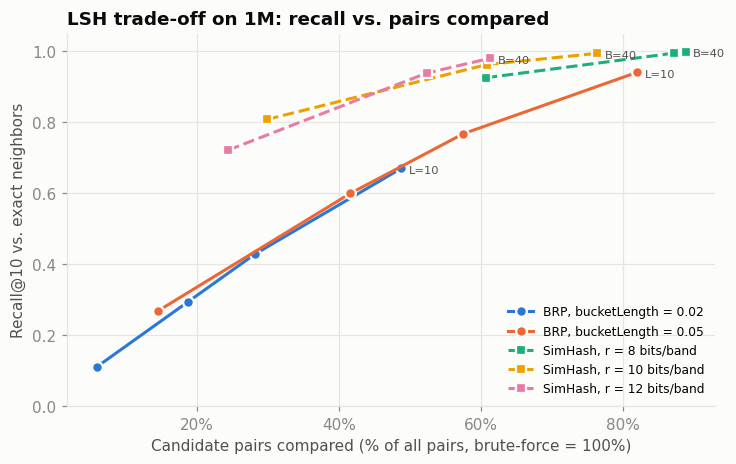

Saved results/bf_vs_lsh_time_1m.png


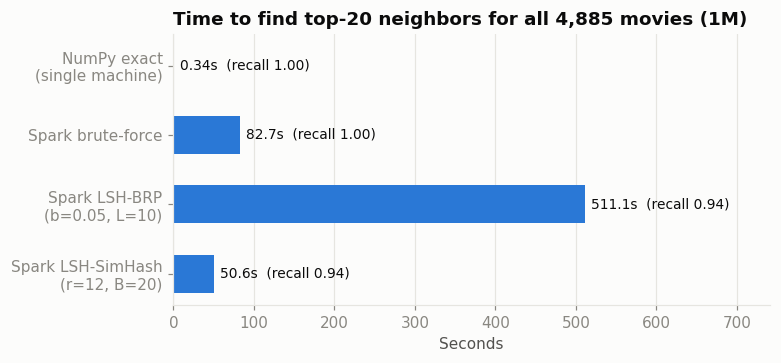

In [12]:
PALETTE = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4", "#008300"]   # thu tu co dinh
series = ([("LSH-BRP", "bucketLength", v, "numHashTables", "L", f"BRP, bucketLength = {v}") for v in LSH_BUCKETS] +
          [("LSH-SimHash", "bits_per_band", v, "bands", "B", f"SimHash, r = {v} bits/band") for v in SH_BITS])
fig, ax = plt.subplots(figsize=(7.6, 4.4))
for (meth, col, v, xcol, tag, label), color in zip(series, PALETTE):
    d = res[(res["method"] == meth) & (res[col] == v)].sort_values(xcol)
    ax.plot(d["cand_pct"], d[f"recall@{K}"], color=color, linewidth=2,
            linestyle="-" if meth == "LSH-BRP" else "--", marker="o" if meth == "LSH-BRP" else "s",
            markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
    last = d.iloc[-1]
    ax.annotate(f"{tag}={int(last[xcol])}", (last["cand_pct"], last[f"recall@{K}"]),
                xytext=(5, -3), textcoords="offset points", color=INK2, fontsize=7.5)
ax.set_title(f"LSH trade-off on {SUBSET.upper()}: recall vs. pairs compared")
ax.set_xlabel("Candidate pairs compared (% of all pairs, brute-force = 100%)")
ax.set_ylabel(f"Recall@{K} vs. exact neighbors")
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="lower right", fontsize=8)
save(fig, f"lsh_tradeoff_{SUBSET}"); plt.show()

bars = pd.DataFrame({
    "label": ["NumPy exact\n(single machine)", "Spark brute-force",
              f"Spark LSH-BRP\n({cfg(pick_brp)})", f"Spark LSH-SimHash\n({cfg(pick_sh)})"],
    "time": [numpy_s, bf_s, pick_brp["time_s"], pick_sh["time_s"]],
    "recall": [1.0, bf_recall, pick_brp[f"recall@{K}"], pick_sh[f"recall@{K}"]]})
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(bars["label"], bars["time"], color=BLUE, height=0.55)
for y, (v, rc) in enumerate(zip(bars["time"], bars["recall"])):
    ax.annotate((f"{v:.2f}s" if v < 1 else f"{v:.1f}s") + f"  (recall {rc:.2f})", (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.invert_yaxis()
ax.set_title(f"Time to find top-{K_NB} neighbors for all {n_items:,} movies ({SUBSET.upper()})")
ax.set_xlabel("Seconds")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, bars["time"].max() * 1.45)
save(fig, f"bf_vs_lsh_time_{SUBSET}"); plt.show()

## 8. Summary (copy this to Claude / the handoff)

In [13]:
summary = {
    "subset": SUBSET, "min_ratings": MIN_RATINGS,
    "als": {"rank": BEST_RANK, "regParam": BEST_REG, "maxIter": ALS_ITER,
            "test_rmse": round(test_rmse, 4), "fit_s": round(als_fit_s, 1)},
    "movies_in_train": n_all, "movies_used": n_items, "pairs": total_pairs,
    "numpy_exact_s": round(numpy_s, 2), "spark_bf_s": round(bf_s, 1), "spark_bf_recall": round(bf_recall, 4),
    "best_brp": {"config": cfg(pick_brp), "cand_pct": float(pick_brp["cand_pct"]), "time_s": float(pick_brp["time_s"]),
                 "speedup_vs_bf": float(pick_brp["speedup_vs_bf"]), "recall": float(pick_brp[f"recall@{K}"]),
                 "precision": float(pick_brp[f"precision@{K}"])},
    "best_simhash": {"config": cfg(pick_sh), "cand_pct": float(pick_sh["cand_pct"]), "time_s": float(pick_sh["time_s"]),
                     "speedup_vs_bf": float(pick_sh["speedup_vs_bf"]), "recall": float(pick_sh[f"recall@{K}"]),
                     "precision": float(pick_sh[f"precision@{K}"])},
    "precision@10": {"popularity": round(pop_p, 4), "item_based_bf": round(bf_p, 4)},
    "users_evaluated": n_eval,
}
with open(f"results/summary_{SUBSET}.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
shutil.rmtree("work", ignore_errors=True)   # xoa bang lang gieng tam

{
  "subset": "1m",
  "min_ratings": 20,
  "als": {
    "rank": 40,
    "regParam": 0.1,
    "maxIter": 10,
    "test_rmse": 0.8237,
    "fit_s": 18.7
  },
  "movies_in_train": 18662,
  "movies_used": 4885,
  "pairs": 23858340,
  "numpy_exact_s": 0.34,
  "spark_bf_s": 82.7,
  "spark_bf_recall": 1.0,
  "best_brp": {
    "config": "b=0.05, L=10",
    "cand_pct": 82.01,
    "time_s": 511.1,
    "speedup_vs_bf": 0.16,
    "recall": 0.9404,
    "precision": 0.0834
  },
  "best_simhash": {
    "config": "r=12, B=20",
    "cand_pct": 52.36,
    "time_s": 50.6,
    "speedup_vs_bf": 1.63,
    "recall": 0.9384,
    "precision": 0.0834
  },
  "precision@10": {
    "popularity": 0.12,
    "item_based_bf": 0.0837
  },
  "users_evaluated": 6404
}
